# Clustering Voice Dataset Based on Gender

In this notebook, we aim to **cluster a voice dataset** to distinguish between different genders using learning techniques.

## Objectives
- Apply **at least two clustering algorithms** to the dataset.
- Determine the **optimal number of clusters** using the **Silhouette Score**.
- Analyze and compare the performance of the clustering models.

## Key Steps
1. **Data Loading:** Import the final preprocessed dataset.
2. **Exploratory Data Analysis (EDA):** Quick insights into the data distribution.
3. **Modeling:**
   - Apply **K-Means Clustering** and **DBSCAN**.
   - Evaluate each model using the **Silhouette Score** to determine the best number of clusters.


# Imports and Settings

In [83]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns

from sklearn.metrics import silhouette_score, pairwise_distances_argmin_min
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN
from sklearn.cluster import AgglomerativeClustering
from scipy.spatial.distance import pdist, squareform
import numpy as np

# Loading Dataset

In [9]:
df = pd.read_csv('final_dataset.csv')
excluded_columns = ["question_number",
                    "student_id",
                    "has_intro",
                    "file_name",
                    "gender"]
data = df.copy()
df = df.drop(columns=excluded_columns)

# EDA

## Summary Statistics

 Display descriptive statistics (mean, median, standard deviation) to understand feature distributions.


In [10]:
df.describe()

,zero_crossing_rate,energy,spectral_centroid,spectral_bandwidth,log_mel_1,log_mel_2,log_mel_3,log_mel_4,log_mel_5,log_mel_6,...,mfcc_11,mfcc_12,mfcc_13,spectral_contrast_1,spectral_contrast_2,spectral_contrast_3,spectral_contrast_4,spectral_contrast_5,spectral_contrast_6,spectral_contrast_7
count,821.000000,821.000000,821.000000,821.000000,821.000000,821.000000,821.000000,821.000000,821.000000,821.000000,...,821.000000,821.000000,821.000000,821.000000,821.000000,821.000000,821.000000,821.000000,821.000000,821.000000
mean,0.054954,0.170976,1893.056793,1929.081328,-24.408357,-20.533612,-19.026207,-23.217894,-30.253764,-35.060643,...,-11.632443,-2.817423,-4.180447,17.667740,14.178068,19.442202,19.898673,22.756795,31.342683,31.292369
std,0.055693,0.026658,1285.677087,414.365355,11.105592,10.241122,10.655355,11.713222,11.641152,10.884943,...,9.536162,8.598965,9.469299,3.597710,2.438562,2.943168,2.643634,2.429598,4.304217,6.560196
min,0.006679,0.001929,676.703972,1094.504697,-69.511160,-69.631996,-70.493220,-70.769890,-71.311760,-71.659270,...,-44.516323,-32.578854,-30.792100,6.134539,5.500055,7.212382,8.723677,14.126717,15.918311,13.496614
25%,0.027361,0.164994,1240.350891,1642.914456,-30.456938,-24.566574,-22.241800,-28.678220,-37.371340,-41.897877,...,-17.692337,-8.758240,-10.399458,15.196449,12.764616,17.941771,18.356203,21.076658,28.461698,27.175248
50%,0.035740,0.174484,1482.816332,1859.053958,-22.466913,-18.233969,-15.703797,-21.320694,-29.064032,-34.157158,...,-11.756716,-2.869582,-4.863769,18.348865,14.183379,19.654289,20.060046,22.618777,31.304603,30.850208
75%,0.055541,0.184325,1934.814207,2125.475898,-16.285906,-13.515914,-12.299141,-14.575443,-21.959051,-27.073206,...,-5.480535,3.029158,1.903227,20.481872,15.682439,21.421342,21.611011,24.315244,34.211570,35.127551
max,0.389508,0.255353,9404.544156,3828.028079,-4.265939,-5.610474,-4.974742,-5.276269,-7.448854,-10.938334,...,27.399490,24.490343,29.624844,26.220016,22.694689,26.313290,29.945191,31.761034,44.890301,50.992761


# Feature selection

In [43]:
def get_corr(data):
    num_cols = data.select_dtypes(include=['int64', 'float64']).columns   
    corr_matrix = data[num_cols].corr()
    upper_triangle = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    high_corr_features = [(column, upper_triangle[column].idxmax(), upper_triangle[column].max()) for column in upper_triangle.columns if any(upper_triangle[column] > 0.9)]
    for feature1, feature2, corr_value in high_corr_features:
        print(f"{feature1} and {feature2} have a correlation of {corr_value}")
    return corr_matrix

In [45]:
corr_matrix = get_corr(df)

spectral_centroid and zero_crossing_rate have a correlation of 0.9881841285515741
log_mel_5 and log_mel_4 have a correlation of 0.9477458535942098
log_mel_6 and log_mel_5 have a correlation of 0.9674627552423725
log_mel_7 and log_mel_6 have a correlation of 0.9574777163616951
log_mel_8 and log_mel_7 have a correlation of 0.9396201015580519
log_mel_12 and log_mel_11 have a correlation of 0.9040652333066013
log_mel_17 and log_mel_16 have a correlation of 0.9333421186799015
log_mel_18 and log_mel_17 have a correlation of 0.9321549391243034
log_mel_19 and log_mel_18 have a correlation of 0.9187302232701716
log_mel_20 and log_mel_19 have a correlation of 0.9418945927958875
log_mel_21 and log_mel_20 have a correlation of 0.962770181023063
log_mel_22 and log_mel_21 have a correlation of 0.9598337652363932


In [46]:
log_mel_features = [col for col in df.columns if "log_mel" in col]
log_mel_data = df[log_mel_features]

scaler = StandardScaler()
log_mel_scaled = scaler.fit_transform(log_mel_data)

pca = PCA(n_components=0.95)
log_mel_pca = pca.fit_transform(log_mel_scaled)

pca_columns = [f"log_mel_pca_{i}" for i in range(log_mel_pca.shape[1])]
df_pca = pd.DataFrame(log_mel_pca, columns=pca_columns)

df = df.drop(columns=log_mel_features)
df.reset_index(drop=True, inplace=True)
df_pca.reset_index(drop=True, inplace=True)
df = pd.concat([df, df_pca], axis=1)

print(f"Original log-mel features: {len(log_mel_features)}, Reduced to: {len(pca_columns)}")

Original log-mel features: 23, Reduced to: 8


In [47]:
df.drop(columns=['zero_crossing_rate', 'log_mel_pca_0'], inplace=True)

In [48]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 821 entries, 0 to 820
Data columns (total 30 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   energy               821 non-null    float64
 1   spectral_centroid    821 non-null    float64
 2   spectral_bandwidth   821 non-null    float64
 3   mfcc_1               821 non-null    float64
 4   mfcc_2               821 non-null    float64
 5   mfcc_3               821 non-null    float64
 6   mfcc_4               821 non-null    float64
 7   mfcc_5               821 non-null    float64
 8   mfcc_6               821 non-null    float64
 9   mfcc_7               821 non-null    float64
 10  mfcc_8               821 non-null    float64
 11  mfcc_9               821 non-null    float64
 12  mfcc_10              821 non-null    float64
 13  mfcc_11              821 non-null    float64
 14  mfcc_12              821 non-null    float64
 15  mfcc_13              821 non-null    flo

# Clustering

Before starting, let's standardize the data.

In [49]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df)

Also use PCA for visualizing data

In [50]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(scaled_data)

## KMeans

### Similarity and Dissimilarity

In [51]:
def euclidean_distance(a, b):
    return np.linalg.norm(a - b)

def similarity_and_dissimilarity_report(kmeans_model: KMeans):
  centroids = kmeans_model.cluster_centers_
  num_clusters = len(centroids)
  dissimilarity_matrix = np.zeros((num_clusters, num_clusters))

  for i in range(num_clusters):
    for j in range(num_clusters):
      if i != j:
        dissimilarity_matrix[i, j] = euclidean_distance(centroids[i], centroids[j])

  similarity_matrix = 1 / (1 + dissimilarity_matrix)

  print("Dissimilarity Matrix (Euclidean Distance):")
  print(dissimilarity_matrix)

  print("\nSimilarity Matrix (Inverse of Euclidean Distance):")
  print(similarity_matrix)

  print("\nMin and Max Dissimilarity:")
  print(f"Min: {np.min(dissimilarity_matrix)} | Max: {np.max(dissimilarity_matrix)}")

  print("\nMin and Max Similarity:")
  print(f"Min: {np.min(similarity_matrix)} | Max: {np.max(similarity_matrix)}")

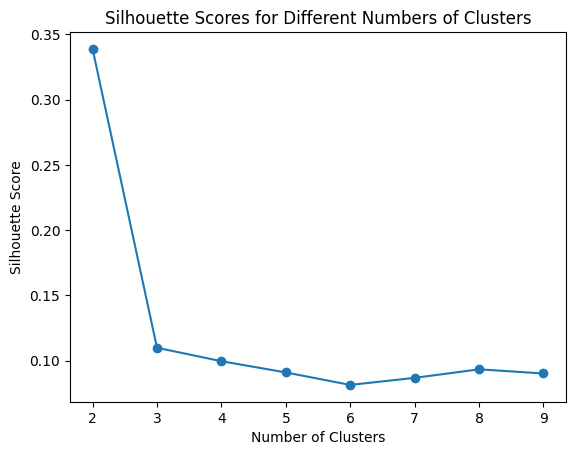

The best number of clusters is: 2


In [52]:
sil_scores = []
range_clusters = range(2, 10)

for n_clusters in range_clusters:
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    kmeans.fit(scaled_data)
    cluster_labels = kmeans.labels_

    score = silhouette_score(scaled_data, cluster_labels)
    sil_scores.append(score)

plt.plot(range_clusters, sil_scores, marker='o')
plt.title('Silhouette Scores for Different Numbers of Clusters')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.show()

best_n_clusters = range_clusters[np.argmax(sil_scores)]
print(f"The best number of clusters is: {best_n_clusters}")

### n_clusters = 2

In [53]:
kmeans2 = KMeans(n_clusters=2, random_state=42)
kmeans2.fit(scaled_data)

KMeans(n_clusters=2, random_state=42)

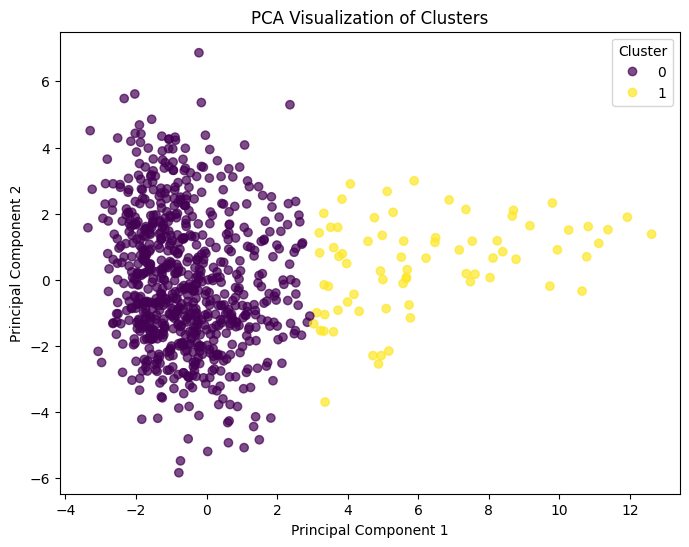

In [54]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans2.labels_, cmap='viridis', alpha=0.7)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Clusters")
plt.legend(*scatter.legend_elements(), title="Cluster")
plt.show()

In [79]:
def analyze_clusters(data, kmeans_labels):
    data['cluster'] = kmeans_labels

    gender_counts = data.groupby(['cluster', 'gender']).size().unstack(fill_value=0)
    numeric_data = data.select_dtypes(include=[np.number])
    feature_means = numeric_data.groupby(data['cluster']).mean()

    print(gender_counts)
    print("energy",feature_means['energy'])

    feature_diffs = feature_means.diff().iloc[-1].abs()
    most_diff_feature = feature_diffs.idxmax()
    print(f"The feature with the most difference between clusters is: {most_diff_feature} with difference:", feature_diffs.max()) 
    for cluster in range(len(np.unique(kmeans_labels))):
        print(f"Cluster {cluster} has {len(kmeans_labels[kmeans_labels == cluster])} samples")
        print(f"{most_diff_feature} for cluster {cluster} is {feature_means.loc[cluster, most_diff_feature]}")

analyze_clusters(data, kmeans2.labels_)

gender   female  male
cluster              
0           154   593
1            36    38
energy cluster
0    0.173242
1    0.148109
Name: energy, dtype: float64
The feature with the most difference between clusters is: spectral_centroid with difference: 3567.1203509950874
Cluster 0 has 747 samples
spectral_centroid for cluster 0 is 1571.5380276998023
Cluster 1 has 74 samples
spectral_centroid for cluster 1 is 5138.6583786948895


In [56]:
similarity_and_dissimilarity_report(kmeans2)

Dissimilarity Matrix (Euclidean Distance):
[[0.         6.83120795]
 [6.83120795 0.        ]]

Similarity Matrix (Inverse of Euclidean Distance):
[[1.         0.12769422]
 [0.12769422 1.        ]]

Min and Max Dissimilarity:
Min: 0.0 | Max: 6.831207945270873

Min and Max Similarity:
Min: 0.12769422124767893 | Max: 1.0


### n_clusters = 4

In [57]:
kmeans4 = KMeans(n_clusters=4, random_state=42)
kmeans4.fit(scaled_data)

KMeans(n_clusters=4, random_state=42)

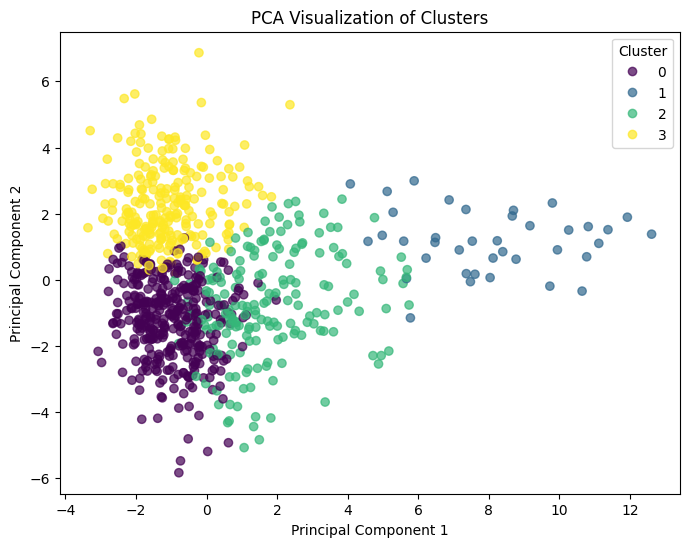

In [58]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans4.labels_, cmap='viridis', alpha=0.7)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Clusters")
plt.legend(*scatter.legend_elements(), title="Cluster")
plt.show()

In [80]:
analyze_clusters(data, kmeans4.labels_)

gender   female  male
cluster              
0            84   275
1            25    13
2            35   148
3            46   195
energy cluster
0    0.176364
1    0.158087
2    0.161822
3    0.171934
Name: energy, dtype: float64
The feature with the most difference between clusters is: spectral_centroid with difference: 749.2424955903316
Cluster 0 has 359 samples
spectral_centroid for cluster 0 is 1361.3981009915394
Cluster 1 has 38 samples
spectral_centroid for cluster 1 is 6638.643239506756
Cluster 2 has 183 samples
spectral_centroid for cluster 2 is 2343.765817913266
Cluster 3 has 241 samples
spectral_centroid for cluster 3 is 1594.5233223229343


In [59]:
similarity_and_dissimilarity_report(kmeans4)

Dissimilarity Matrix (Euclidean Distance):
[[0.         9.48875294 3.303682   3.61293742]
 [9.48875294 0.         7.30502457 9.46137776]
 [3.303682   7.30502457 0.         4.32226374]
 [3.61293742 9.46137776 4.32226374 0.        ]]

Similarity Matrix (Inverse of Euclidean Distance):
[[1.         0.09534022 0.23235918 0.21678161]
 [0.09534022 1.         0.12040904 0.0955897 ]
 [0.23235918 0.12040904 1.         0.18788997]
 [0.21678161 0.0955897  0.18788997 1.        ]]

Min and Max Dissimilarity:
Min: 0.0 | Max: 9.488752936413926

Min and Max Similarity:
Min: 0.0953402188098347 | Max: 1.0


### n_clusters = 7

In [60]:
kmeans7 = KMeans(n_clusters=7, random_state=42)
kmeans7.fit(scaled_data)

KMeans(n_clusters=7, random_state=42)

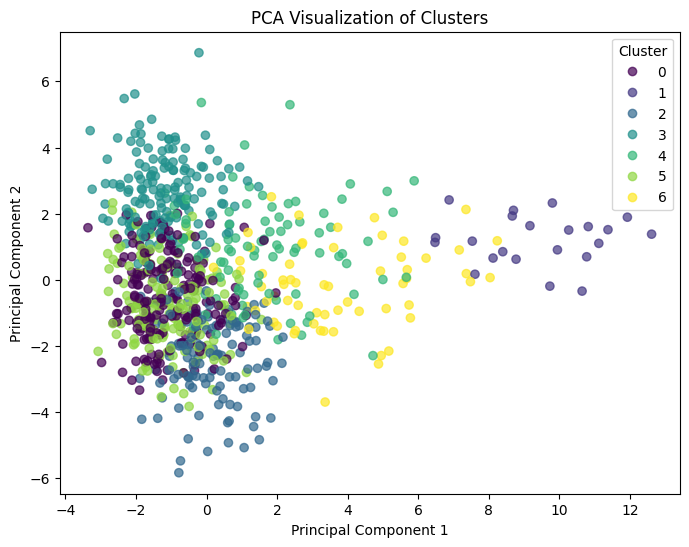

In [61]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans7.labels_, cmap='viridis', alpha=0.7)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Clusters")
plt.legend(*scatter.legend_elements(), title="Cluster")
plt.show()

In [81]:
analyze_clusters(data, kmeans7.labels_)

gender   female  male
cluster              
0            69   136
1            14     8
2             9   111
3            21   136
4            52    35
5             4   164
6            21    41
energy cluster
0    0.176690
1    0.164556
2    0.178150
3    0.170343
4    0.174638
5    0.170416
6    0.138466
Name: energy, dtype: float64
The feature with the most difference between clusters is: spectral_centroid with difference: 1818.7904597928446
Cluster 0 has 205 samples
spectral_centroid for cluster 0 is 1397.7013537504267
Cluster 1 has 22 samples
spectral_centroid for cluster 1 is 7559.990493944875
Cluster 2 has 120 samples
spectral_centroid for cluster 2 is 1340.5251658257646
Cluster 3 has 157 samples
spectral_centroid for cluster 3 is 1546.7056353107603
Cluster 4 has 87 samples
spectral_centroid for cluster 4 is 2900.4466540460166
Cluster 5 has 168 samples
spectral_centroid for cluster 5 is 1445.8755925109072
Cluster 6 has 62 samples
spectral_centroid for cluster 6 is 3264.666052

In [62]:
similarity_and_dissimilarity_report(kmeans7)

Dissimilarity Matrix (Euclidean Distance):
[[ 0.         11.25616274  3.4722258   3.85120894  4.26710668  2.99005763
   5.86881465]
 [11.25616274  0.         10.90734095 11.43444826  9.032797   11.38035334
   8.54685687]
 [ 3.4722258  10.90734095  0.          5.25278745  4.93210169  3.53402344
   5.26451671]
 [ 3.85120894 11.43444826  5.25278745  0.          4.71728229  4.13024047
   6.24863659]
 [ 4.26710668  9.032797    4.93210169  4.71728229  0.          4.17370634
   5.39430531]
 [ 2.99005763 11.38035334  3.53402344  4.13024047  4.17370634  0.
   5.92424728]
 [ 5.86881465  8.54685687  5.26451671  6.24863659  5.39430531  5.92424728
   0.        ]]

Similarity Matrix (Inverse of Euclidean Distance):
[[1.         0.08159161 0.22360231 0.20613418 0.18985756 0.25062295
  0.14558553]
 [0.08159161 1.         0.08398181 0.08042174 0.0996731  0.08077314
  0.10474652]
 [0.22360231 0.08398181 1.         0.15992867 0.16857432 0.22055466
  0.15962923]
 [0.20613418 0.08042174 0.15992867 1.      

## Agglomerative Clustering

In [82]:
# from scipy.spatial.distance import pdist, squareform

# def similarity_and_dissimilarity_report(agg_model: AgglomerativeClustering, data: np.ndarray):
#     pairwise_distances = squareform(pdist(data))

#     labels = agg_model.labels_
#     num_clusters = len(np.unique(labels))

#     dissimilarity_matrix = np.zeros((num_clusters, num_clusters))

#     for i in range(num_clusters):
#         for j in range(num_clusters):
#             if i != j:
#                 cluster_i = data[labels == i]
#                 cluster_j = data[labels == j]
#                 dissimilarity_matrix[i, j] = np.mean(pdist(np.vstack([cluster_i, cluster_j])))

#     similarity_matrix = 1 / (1 + dissimilarity_matrix)

#     print("Dissimilarity Matrix (Mean Pairwise Distance):")
#     print(dissimilarity_matrix)

#     print("\nSimilarity Matrix (Inverse of Mean Pairwise Distance):")
#     print(similarity_matrix)

#     print("\nMin and Max Dissimilarity:")
#     print(f"Min: {np.min(dissimilarity_matrix[dissimilarity_matrix > 0])} | Max: {np.max(dissimilarity_matrix)}")

#     print("\nMin and Max Similarity:")
#     print(f"Min: {np.min(similarity_matrix[similarity_matrix > 0])} | Max: {np.max(similarity_matrix)}")

In [84]:
def similarity_and_dissimilarity_report(agg_model: AgglomerativeClustering, data: np.ndarray):
    if not hasattr(agg_model, 'labels_'):
        raise ValueError("AgglomerativeClustering model must be fitted before calling this function.")

    labels = agg_model.labels_
    num_clusters = len(np.unique(labels))

    dissimilarity_matrix = np.zeros((num_clusters, num_clusters))

    for i in range(num_clusters):
        for j in range(num_clusters):
            if i != j:
                cluster_i = data[labels == i]
                cluster_j = data[labels == j]
                # Compute pairwise distance between two clusters (all pairs from cluster_i and cluster_j)
                dissimilarity_matrix[i, j] = np.mean(pdist(np.vstack([cluster_i, cluster_j])))

    # Similarity is the inverse of dissimilarity
    similarity_matrix = 1 / (1 + dissimilarity_matrix)

    print("Dissimilarity Matrix (Mean Pairwise Distance):")
    print(dissimilarity_matrix)

    print("\nSimilarity Matrix (Inverse of Mean Pairwise Distance):")
    print(similarity_matrix)

    print("\nMin and Max Dissimilarity:")
    print(f"Min: {np.min(dissimilarity_matrix[dissimilarity_matrix > 0])} | Max: {np.max(dissimilarity_matrix)}")

    print("\nMin and Max Similarity:")
    print(f"Min: {np.min(similarity_matrix[similarity_matrix > 0])} | Max: {np.max(similarity_matrix)}")

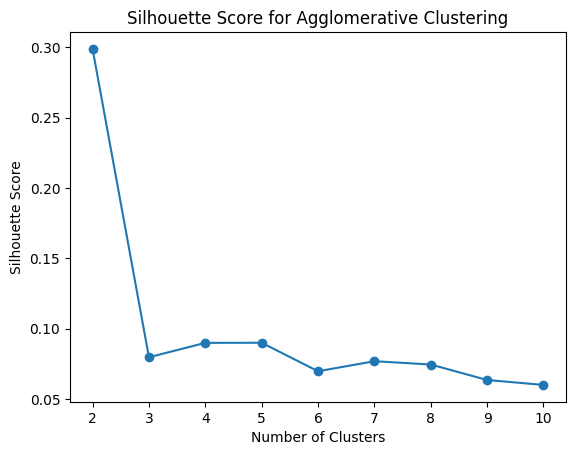

Best number of clusters based on Silhouette Score: 2


In [85]:
cluster_range = range(2, 11)
sil_scores = []

for n_clusters in cluster_range:
    agg_clustering = AgglomerativeClustering(n_clusters=n_clusters)
    agg_labels = agg_clustering.fit_predict(scaled_data)
    sil_score = silhouette_score(scaled_data, agg_labels)
    sil_scores.append(sil_score)

plt.plot(cluster_range, sil_scores, marker='o')
plt.title('Silhouette Score for Agglomerative Clustering')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.show()

best_k = cluster_range[sil_scores.index(max(sil_scores))]
print(f'Best number of clusters based on Silhouette Score: {best_k}')

### n_cluster = 2

In [86]:
agg_clustering2 = AgglomerativeClustering(n_clusters=2)
agg_labels2 = agg_clustering2.fit_predict(scaled_data)

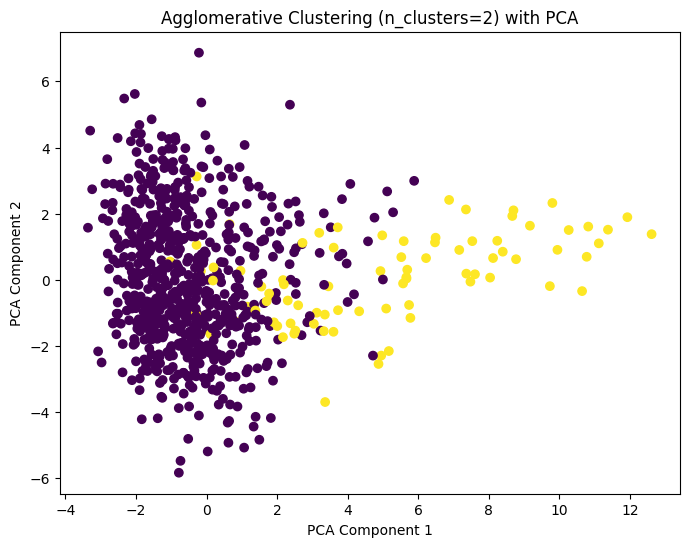

In [87]:
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=agg_labels2, cmap='viridis', marker='o')
plt.title(f'Agglomerative Clustering (n_clusters=2) with PCA')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.show()

In [89]:
analyze_clusters(data, agg_labels2)

gender   female  male
cluster              
0           153   585
1            37    46
energy cluster
0    0.174803
1    0.136951
Name: energy, dtype: float64
The feature with the most difference between clusters is: spectral_centroid with difference: 2613.5906035449325
Cluster 0 has 738 samples
spectral_centroid for cluster 0 is 1628.832651182637
Cluster 1 has 83 samples
spectral_centroid for cluster 1 is 4242.42325472757


In [88]:
similarity_and_dissimilarity_report(agg_clustering2, scaled_data)

Dissimilarity Matrix (Mean Pairwise Distance):
[[0.         7.41087442]
 [7.41087442 0.        ]]

Similarity Matrix (Inverse of Mean Pairwise Distance):
[[1.        0.1188937]
 [0.1188937 1.       ]]

Min and Max Dissimilarity:
Min: 7.410874419330782 | Max: 7.410874419330785

Min and Max Similarity:
Min: 0.11889370238386765 | Max: 1.0


### n_cluster = 4

In [66]:
agg_clustering4 = AgglomerativeClustering(n_clusters=4)
agg_labels4 = agg_clustering4.fit_predict(scaled_data)

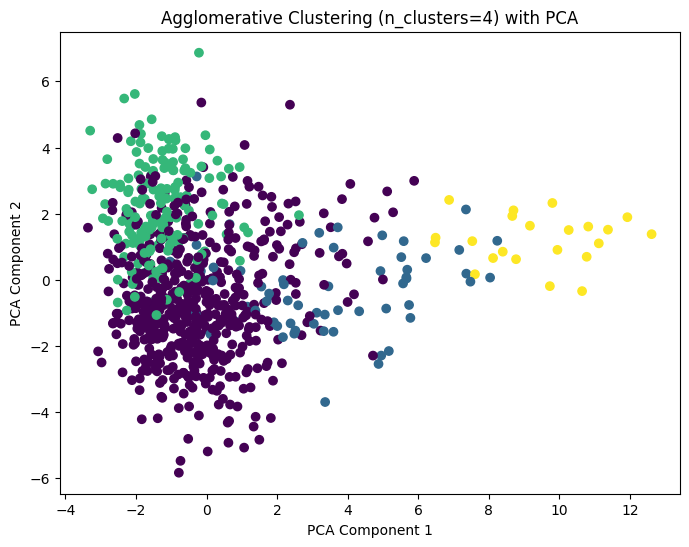

In [67]:
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=agg_labels4, cmap='viridis', marker='o')
plt.title(f'Agglomerative Clustering (n_clusters=4) with PCA')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.show()

In [91]:
analyze_clusters(data, agg_labels4)

gender   female  male
cluster              
0           134   429
1            23    38
2            19   156
3            14     8
energy cluster
0    0.174883
1    0.126995
2    0.174546
3    0.164556
Name: energy, dtype: float64
The feature with the most difference between clusters is: spectral_centroid with difference: 6084.313827473605
Cluster 0 has 563 samples
spectral_centroid for cluster 0 is 1676.4388631266672
Cluster 1 has 61 samples
spectral_centroid for cluster 1 is 3045.9235946819845
Cluster 2 has 175 samples
spectral_centroid for cluster 2 is 1475.6766664712702
Cluster 3 has 22 samples
spectral_centroid for cluster 3 is 7559.990493944875


In [92]:
similarity_and_dissimilarity_report(agg_clustering4, scaled_data)

Dissimilarity Matrix (Mean Pairwise Distance):
[[0.         7.07438907 6.76480688 7.02713552]
 [7.07438907 0.         7.5672238  9.90157399]
 [6.76480688 7.5672238  0.         7.45375035]
 [7.02713552 9.90157399 7.45375035 0.        ]]

Similarity Matrix (Inverse of Mean Pairwise Distance):
[[1.         0.12384838 0.1287862  0.12457744]
 [0.12384838 1.         0.11672393 0.09172987]
 [0.1287862  0.11672393 1.         0.11829069]
 [0.12457744 0.09172987 0.11829069 1.        ]]

Min and Max Dissimilarity:
Min: 6.764806882049706 | Max: 9.901573985734045

Min and Max Similarity:
Min: 0.09172987325578988 | Max: 1.0


### n_cluster = 7

In [93]:
agg_clustering7 = AgglomerativeClustering(n_clusters=7)
agg_labels7 = agg_clustering7.fit_predict(scaled_data)

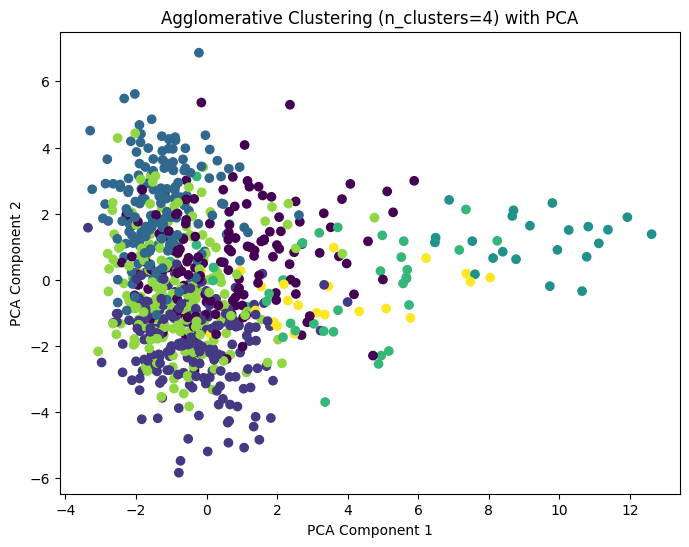

In [94]:
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=agg_labels7, cmap='viridis', marker='o')
plt.title(f'Agglomerative Clustering (n_clusters=4) with PCA')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.show()

In [95]:
analyze_clusters(data, agg_labels7)

gender   female  male
cluster              
0           107    39
1            24   193
2            19   156
3            14     8
4            15    23
5             3   197
6             8    15
energy cluster
0    0.175158
1    0.179319
2    0.174546
3    0.164556
4    0.099711
5    0.169868
6    0.172074
Name: energy, dtype: float64
The feature with the most difference between clusters is: spectral_centroid with difference: 1847.280736530001
Cluster 0 has 146 samples
spectral_centroid for cluster 0 is 2381.5709407519917
Cluster 1 has 217 samples
spectral_centroid for cluster 1 is 1357.5208147405933
Cluster 2 has 175 samples
spectral_centroid for cluster 2 is 1475.6766664712702
Cluster 3 has 22 samples
spectral_centroid for cluster 3 is 7559.990493944875
Cluster 4 has 38 samples
spectral_centroid for cluster 4 is 2858.8514781408526
Cluster 5 has 200 samples
spectral_centroid for cluster 5 is 1507.7185289590707
Cluster 6 has 23 samples
spectral_centroid for cluster 6 is 3354.9992654

In [96]:
similarity_and_dissimilarity_report(agg_clustering7, scaled_data)

Dissimilarity Matrix (Mean Pairwise Distance):
[[0.         6.66466444 6.76745408 7.68536653 7.44182534 6.55176921
  7.19117902]
 [6.66466444 0.         6.60520427 7.11900463 6.82455409 6.24727641
  6.48962503]
 [6.76745408 6.60520427 0.         7.45375035 7.14148189 6.44643179
  6.76162599]
 [7.68536653 7.11900463 7.45375035 0.         9.76549386 7.16218878
  9.52004457]
 [7.44182534 6.82455409 7.14148189 9.76549386 0.         6.87777184
  8.92916551]
 [6.55176921 6.24727641 6.44643179 7.16218878 6.87777184 0.
  6.56417672]
 [7.19117902 6.48962503 6.76162599 9.52004457 8.92916551 6.56417672
  0.        ]]

Similarity Matrix (Inverse of Mean Pairwise Distance):
[[1.         0.13046886 0.12874231 0.11513619 0.11845779 0.1324193
  0.12208255]
 [0.13046886 1.         0.13148891 0.12316781 0.12780281 0.13798287
  0.13351803]
 [0.12874231 0.13148891 1.         0.11829069 0.12282776 0.13429251
  0.12883898]
 [0.11513619 0.12316781 0.11829069 1.         0.09288938 0.12251616
  0.09505663]
 [0

# DBscan

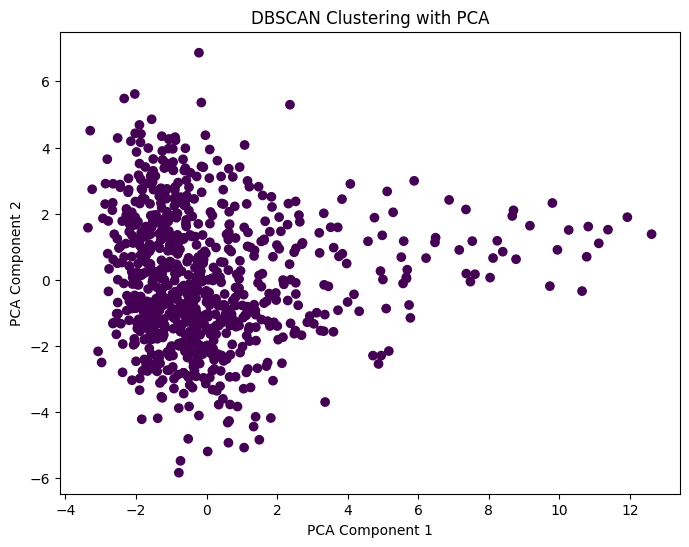

In [70]:
dbscan = DBSCAN(eps=0.5, min_samples=5)

dbscan_labels = dbscan.fit_predict(scaled_data)

# Plot the clusters
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=dbscan_labels, cmap='viridis', marker='o')
plt.title('DBSCAN Clustering with PCA')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.show()